### Step 1: Install Required Libraries

We will begin by installing qiskit, qiskit-aer for local quantum simulation, matplotlib for plotting, and pylatexenc for high-quality circuit visualizations.

In [1]:
!pip install qiskit qiskit-aer matplotlib pylatexenc

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.5/9.5 MB 101.5 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 14.2/14.2 MB 78.2 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 101.4 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5/5 [qiskit-aer]


### Step 2: Create a Superposition State

Using a single-qubit quantum circuit, we apply a **Hadamard (H) gate** to put the qubit in a superposition state:

$$\frac{|0\rangle + |1\rangle}{\sqrt{2}}$$

In [4]:
from qiskit import QuantumCircuit
qc=QuantumCircuit(1)
qc.h(0)
print(qc.draw())

   ┌───┐
q: ┤ H ├
   └───┘


### Step 3: Extract the Statevector

We can inspect the exact mathematical state of the qubit by extracting its statevector representation.

In [5]:
from qiskit.quantum_info import Statevector
state=Statevector.from_instruction(qc)
print(state.data)

[0.70710678+0.j 0.70710678+0.j]


### Step 4: Visualize Measurement Results with plot_histogram()

Here, we apply a **Pauli-Z gate**, perform a measurement, and run a simulation using `AerSimulator` to collect the experimental counts.

     ┌───┐┌─┐
  q: ┤ Z ├┤M├
     └───┘└╥┘
c: 1/══════╩═
           0 


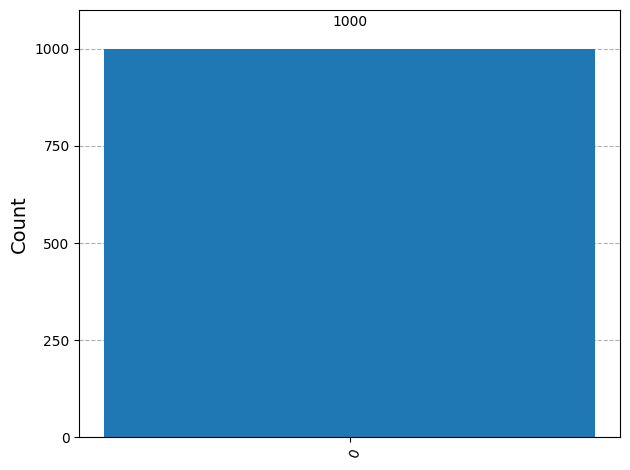

In [22]:
%matplotlib inline
import matplotlib.pyplot as plt
from qiskit import QuantumCircuit
from qiskit_aer import AerSimulator
from qiskit.visualization import plot_histogram
import matplotlib.pyplot as plt
qc=QuantumCircuit(1,1)
qc.z(0)
qc.measure(0,0)
print(qc.draw())
simulator=AerSimulator()
job=simulator.run(qc,shots=1000)
result=job.result()
count=result.get_counts(qc)
fig=plot_histogram(count)
display(fig)

### Step 5: Visualize the State on a Bloch Sphere

We visualize the exact quantum state on the Bloch Sphere using plot_bloch_multivector().

Note: To obtain the exact statevector, we must avoid adding measurement gates (measure) prior to extracting the state.

     ┌───┐
  q: ┤ Z ├
     └───┘
c: 1/═════
          


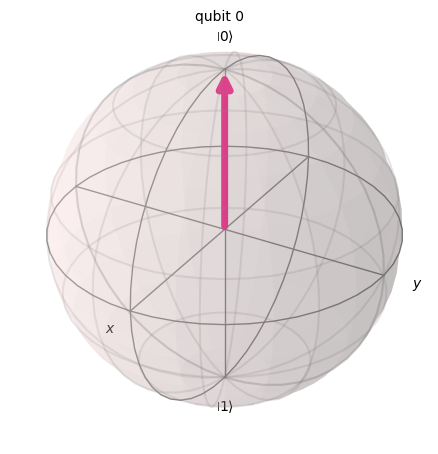

In [28]:
%matplotlib inline
import matplotlib.pyplot as plt
from qiskit import QuantumCircuit
from qiskit.quantum_info import Statevector
from qiskit.visualization import plot_bloch_multivector
import matplotlib.pyplot as plt
qc=QuantumCircuit(1,1)
qc.z(0)
print(qc.draw())
state=Statevector.from_instruction(qc)
fig=plot_bloch_multivector(state)
display(fig)

### Step 6: Density Matrix Visualization

We can also compute and visualize the state's density matrix |0> as a 3D bar chart (State City plot).

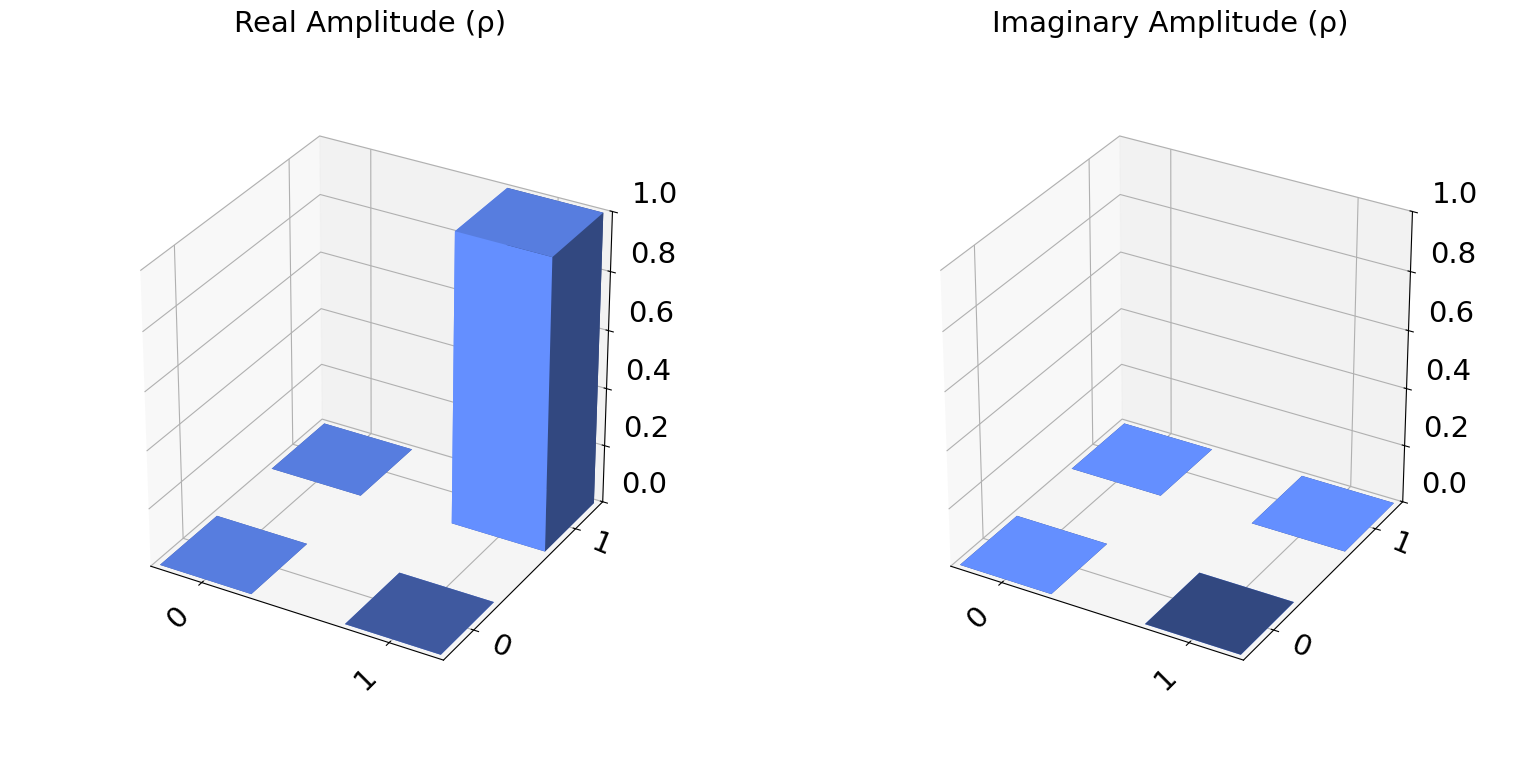

In [30]:
from qiskit import QuantumCircuit
from qiskit.quantum_info import DensityMatrix
from qiskit.visualization import plot_state_city
qc=QuantumCircuit(1)
qc.x(0)
dense=DensityMatrix.from_instruction(qc)
fig=plot_state_city(dense)
display(fig)